<div style="background-color:#0D3B66; color:#FFFFFF; padding:22px; border-radius:8px; text-align:center;">
<h1 style="color:#FFFFFF; margin:0;">🏥 Healthcare Data Patterns and Patient Demographics: Exploratory Data Analysis Using Python 🩺</h1>
</div>

<div style="background-color:#E3F2FD; color:#0D3B66; padding:12px 18px; border-left:6px solid #1565C0; margin-top:8px;">
👩‍💻 <b>Author:</b> Ansania Salam<br>
🐍 <b>Tool:</b> Python (Jupyter Notebook)<br>
📚 <b>Libraries:</b> Pandas, NumPy, Matplotlib, Seaborn
</div>

## 📋 1. Introduction and Project Overview

🩺 **Domain:** Healthcare (hospital patient records and treatment cost analysis)

📋 **About the project:** This project is an exploratory data analysis of hospital admission records. The data shows who was admitted, which medical condition they were treated for, the type of admission, the insurance provider, the medication, the test result, the length of stay and the amount billed. I will use Python to clean the data, explore it, and look for patterns in patient profiles, billing and length of stay.

🎯 **Objectives:**
1. Load the data and understand its structure and quality.
2. Clean the data and create new columns that help the analysis, such as length of stay and age group.
3. Study the patient profile: age, gender, blood type and medical condition.
4. Find out whether billing amount and length of stay differ by medical condition, insurance provider, admission type and age group.
5. Look at how admissions change over time.
6. Summarise the main findings and suggest next steps.

## 📂 2. Data Description

- 🌐 **Source:** Kaggle, [Healthcare Dataset](https://www.kaggle.com/datasets/prasad22/healthcare-dataset) (file: `healthcare_dataset.csv`)
- 📏 **Size:** 55,500 rows and 15 columns
- 🧾 **What each row means:** One hospital admission record for one patient
- 📅 **Time period:** Admissions from May 2019 to May 2024
- 🔢 **Column types:** A mix of numeric columns (Age, Billing Amount, Room Number), categorical columns (such as Gender, Medical Condition, Admission Type) and date columns (Date of Admission, Discharge Date)

## 📖 3. Column Description

| Column | Data Type | Description | Values / Range |
|---|---|---|---|
| Name | Text (str) | Name of the patient | Text; capitalisation is inconsistent |
| Age | Integer (int64) | Age of the patient in years | 13 to 89 |
| Gender | Text (str) | Gender of the patient | Female, Male |
| Blood Type | Text (str) | Blood group of the patient | A+, A-, AB+, AB-, B+, B-, O+, O- |
| Medical Condition | Text (str) | Condition the patient was admitted for | Arthritis, Asthma, Cancer, Diabetes, Hypertension, Obesity |
| Date of Admission | Text (str) | Date the patient was admitted | May 2019 to May 2024 |
| Doctor | Text (str) | Doctor in charge of the patient | Text; about 40,000 different names |
| Hospital | Text (str) | Hospital where the patient was admitted | Text; about 40,000 different names |
| Insurance Provider | Text (str) | Patient's insurance company | Aetna, Blue Cross, Cigna, Medicare, UnitedHealthcare |
| Billing Amount | Decimal (float64) | Amount billed for the stay | About -2,008 to 52,764 (average about 25,539) |
| Room Number | Integer (int64) | Room assigned to the patient | 101 to 500 |
| Admission Type | Text (str) | How the patient was admitted | Elective, Emergency, Urgent |
| Discharge Date | Text (str) | Date the patient was discharged | Stays last 1 to 30 days |
| Medication | Text (str) | Medicine prescribed | Aspirin, Ibuprofen, Lipitor, Paracetamol, Penicillin |
| Test Results | Text (str) | Outcome of the medical tests | Abnormal, Inconclusive, Normal |

## 🔍 4. Initial Observations

- ✅ **Missing Values:** The dataset has no missing values.
- ♻️ **Duplicates:** The 534 duplicate rows need to be removed.
- 🔤 **Name Column:** Names are written with random capital and small letters (for example "MichAel MILLs") and some start with "DR.", so they need to be standardised. The same name also appears more than once, so it cannot be used as a unique patient ID.
- 🩺 **Doctor Column:** There are around 40,000 different doctor names, so comparing individual doctors will not give useful results.
- 🏨 **Hospital Column:** There are around 40,000 different hospital names, so comparing individual hospitals will not give useful results.
- 📆 **Date Columns:** Date of Admission and Discharge Date are stored as text and must be converted to date format.
- 💰 **Billing Amount:** 108 billing amounts are negative, which is not expected for a bill. These need to be checked and handled.
- 🧩 **Consistent Columns:** Gender, Blood Type, Medical Condition, Insurance Provider, Admission Type, Medication and Test Results have no spelling or formatting inconsistencies.
- ⚖️ **Categories:** Medical condition, insurance provider, admission type and test results are spread almost equally, so large differences between groups may not appear.
- ➕ **New Columns:** Length of stay, age group, admission year and admission month can be created from the existing columns.

# 📥 Data Loading and Initial Overview

## 📚 Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

## 🗂️ Loading the Dataset

The hospital admissions data is loaded from `healthcare_dataset.csv` into a DataFrame named `healthcare_data`. The number of rows and columns is checked right after loading to confirm the file was read in full.

In [2]:
# Read the CSV file into a DataFrame called healthcare_data using Pandas
healthcare_data = pd.read_csv("healthcare_dataset.csv")

In [3]:
# Calling the data
healthcare_data

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal


## 🔎 Basic Data Operations

The following checks give a first overview of the structure, content and quality of the data.

In [4]:
# Total number of rows and columns in the dataset
healthcare_data.shape

(55500, 15)

In [5]:
# Total number of values in the dataset
healthcare_data.size

832500

In [6]:
# Names of all columns in the dataset
healthcare_data.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [7]:
# Retrieving the first five records
healthcare_data.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [8]:
# Retrieve the last five records
healthcare_data.tail()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal
55499,jAMES GARCiA,53,Female,O+,Arthritis,2024-04-02,Dennis Warren,Henry Sons and,Aetna,4010.134172,448,Urgent,2024-04-29,Ibuprofen,Abnormal


In [9]:
# Retrieving the data type of each column
healthcare_data.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [10]:
# Retrieving the column data types and non-null counts
healthcare_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 12.3 MB


In [11]:
# Retrieve summary statistics for the numeric columns
healthcare_data.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [12]:
# Retrieve summary statistics for the numeric columns in transposed form
healthcare_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,55500.0,51.539459,19.602454,13.00000,35.000000,52.000000,68.000000,89.000000
Billing Amount,55500.0,25539.316097,14211.454431,-2008.49214,13241.224652,25538.069376,37820.508436,52764.276736
Room Number,55500.0,301.134829,115.243069,101.00000,202.000000,302.000000,401.000000,500.000000


In [13]:
# Retrieve summary statistics for all columns, including the text columns
healthcare_data.describe(include="all")

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
count,55500,55500.000000,55500,55500,55500,55500,55500,55500,55500,55500.000000,55500.000000,55500,55500,55500,55500
unique,49992,NaN,2,8,6,1827,40341,39876,5,NaN,NaN,3,1856,5,3
top,DAvId muNoZ,NaN,Male,A-,Arthritis,2024-03-16,Michael Smith,LLC Smith,Cigna,NaN,NaN,Elective,2020-03-15,Lipitor,Abnormal
freq,3,NaN,27774,6969,9308,50,27,44,11249,NaN,NaN,18655,53,11140,18627
mean,NaN,51.539459,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25539.316097,301.134829,NaN,NaN,NaN,NaN
std,NaN,19.602454,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14211.454431,115.243069,NaN,NaN,NaN,NaN
min,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2008.492140,101.000000,NaN,NaN,NaN,NaN
25%,NaN,35.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13241.224652,202.000000,NaN,NaN,NaN,NaN
50%,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25538.069376,302.000000,NaN,NaN,NaN,NaN
75%,NaN,68.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37820.508436,401.000000,NaN,NaN,NaN,NaN


In [14]:
# Retrieve the number of unique values in each column
healthcare_data.nunique()

Name                  49992
Age                      77
Gender                    2
Blood Type                8
Medical Condition         6
Date of Admission      1827
Doctor                40341
Hospital              39876
Insurance Provider        5
Billing Amount        50000
Room Number             400
Admission Type            3
Discharge Date         1856
Medication                5
Test Results              3
dtype: int64

In [15]:
# Retrieve the number of records in each category of the categorical columns
categorical_cols = ["Gender", "Blood Type", "Medical Condition", "Insurance Provider",
                    "Admission Type", "Medication", "Test Results"]

for col in categorical_cols:
    print(healthcare_data[col].value_counts())
    print()

Gender
Male      27774
Female    27726
Name: count, dtype: int64

Blood Type
A-     6969
A+     6956
AB+    6947
AB-    6945
B+     6945
B-     6944
O+     6917
O-     6877
Name: count, dtype: int64

Medical Condition
Arthritis       9308
Diabetes        9304
Hypertension    9245
Obesity         9231
Cancer          9227
Asthma          9185
Name: count, dtype: int64

Insurance Provider
Cigna               11249
Medicare            11154
UnitedHealthcare    11125
Blue Cross          11059
Aetna               10913
Name: count, dtype: int64

Admission Type
Elective     18655
Urgent       18576
Emergency    18269
Name: count, dtype: int64

Medication
Lipitor        11140
Ibuprofen      11127
Aspirin        11094
Paracetamol    11071
Penicillin     11068
Name: count, dtype: int64

Test Results
Abnormal        18627
Normal          18517
Inconclusive    18356
Name: count, dtype: int64



In [16]:
# Retrieve the number of duplicate rows
healthcare_data.duplicated().sum()

np.int64(534)

In [17]:
# Retrieve the number of missing values in each column
healthcare_data.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

### 📝 Summary of Basic Data Operations

- 📏 **Size of the Data:** The dataset has 55,500 rows and 15 columns, which gives 832,500 values in total.
- 👀 **First and Last Records:** Each row is one hospital admission. The records show names written with inconsistent capitalisation (for example "Bobby JacksOn") and hospital names with stray words such as "and" at the start or end.
- 🧬 **Data Types:** 12 columns are text, 2 are integer (Age, Room Number) and 1 is decimal (Billing Amount). Date of Admission and Discharge Date are stored as text and need to be converted to dates.
- 📊 **Numeric Summary:** Age ranges from 13 to 89 with an average of about 51.5. Billing Amount ranges from about -2,008 to 52,764 with an average of about 25,539, so some values are negative. Room Number ranges from 101 to 500.
- 🔢 **Unique Values:** Gender (2), Blood Type (8), Medical Condition (6), Insurance Provider (5), Admission Type (3), Medication (5) and Test Results (3) have a small number of categories. Name (49,992), Doctor (40,341) and Hospital (39,876) have very high numbers of unique values.
- 🧮 **Category Counts:** The categories are spread almost equally. For example, Male has 27,774 records, Cigna is the most common insurance provider with 11,249, and Elective is the most common admission type with 18,655.
- ♻️ **Duplicates:** 534 duplicate rows were found.
- ❓ **Missing Values:** No column has missing values.
- ➡️ **Next Step:** The data is complete but needs cleaning: removing duplicates, standardising names, converting the date columns and handling the negative billing amounts.

# 🧹 Data Pre-processing

In this phase the raw data is cleaned and prepared for analysis. The raw DataFrame `healthcare_data` is left unchanged, and all cleaning is done on a working copy called `healthcare_df`. Every step follows the same pattern: check the problem, handle it, and re-check that it is fixed. The steps are done in this order:

1. 🗂️ Create a working copy
2. 🏷️ Check and standardise column names
3. ✂️ Remove extra spaces (strip)
4. 🔧 Check and correct data types
5. 🔤 Standardise text values (proper case, titles, stray words)
6. 🔍 Check category values for inconsistencies
7. ♻️ Check and remove duplicates
8. ❓ Check and handle missing values
9. 🚫 Check and handle invalid values (negative billing, wrong dates)
10. ➕ Create new columns
11. 📦 Check and handle outliers (without plots and with plots)
12. 🗑️ Remove unwanted columns and rows
13. 🔎 Filtering and aggregating the data
14. ✅ Final check and cleaning log
15. 💾 Save the cleaned dataset

## 🗂️ Step 1: Create a Working Copy
A copy of the raw data is made so that the original `healthcare_data` stays available for comparison at the end. A cleaning log is also started to record every change.

In [18]:
# Create a working copy of the raw data
healthcare_df = healthcare_data.copy()

# Store the starting number of rows and create an empty cleaning log
rows_start = healthcare_df.shape[0]
cleaning_log = []

def add_log(step, issue, action, rows_affected):
    # Record one cleaning step in the log
    cleaning_log.append({"Step": step, "Issue": issue, "Action": action, "Rows Affected": rows_affected})

print("Shape of the working copy:", healthcare_df.shape)

Shape of the working copy: (55500, 15)


## 🏷️ Step 2: Check and Standardise Column Names
Column names are checked for extra spaces, unclear abbreviations and inconsistent writing. A name that is unclear would be renamed to a readable Proper Case label.

In [19]:
# Check: current column names and any extra spaces in them
print(list(healthcare_df.columns))
print("\nColumn names with extra spaces:", [col for col in healthcare_df.columns if col != col.strip()])

['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Column names with extra spaces: []


In [20]:
# Handle: remove extra spaces from the column names (no renaming is needed)
healthcare_df.columns = healthcare_df.columns.str.strip()

# Re-check
print("Column names with extra spaces:", [col for col in healthcare_df.columns if col != col.strip()])

Column names with extra spaces: []


**✅ Observation:** The 15 column names are already clear, written in Proper Case and free of extra spaces. No column needed renaming.

## ✂️ Step 3: Remove Extra Spaces (Strip)

Leading and trailing spaces make the same value look different, for example `"Cigna"` and `"Cigna "`. The number of values with extra spaces is checked first, and then they are stripped.

In [21]:
# Text columns in the dataset
text_cols = ["Name", "Gender", "Blood Type", "Medical Condition", "Doctor", "Hospital",
             "Insurance Provider", "Admission Type", "Medication", "Test Results"]

# Check: count the values with extra spaces in each text column
space_check = {col: int((healthcare_df[col] != healthcare_df[col].str.strip()).sum()) for col in text_cols}
print("Values with extra spaces (before strip):")
print(pd.Series(space_check))

Values with extra spaces (before strip):
Name                  0
Gender                0
Blood Type            0
Medical Condition     0
Doctor                0
Hospital              0
Insurance Provider    0
Admission Type        0
Medication            0
Test Results          0
dtype: int64


In [22]:
# Handle: strip leading and trailing spaces in all text columns
for col in text_cols:
    healthcare_df[col] = healthcare_df[col].str.strip()

# Re-check
space_check_after = {col: int((healthcare_df[col] != healthcare_df[col].str.strip()).sum()) for col in text_cols}
print("Values with extra spaces (after strip):")
print(pd.Series(space_check_after))

Values with extra spaces (after strip):
Name                  0
Gender                0
Blood Type            0
Medical Condition     0
Doctor                0
Hospital              0
Insurance Provider    0
Admission Type        0
Medication            0
Test Results          0
dtype: int64


**✅ Observation:** None of the text columns had extra spaces. The strip step stays in the pipeline so that grouping later is not affected by hidden spaces.

## 🔧 Step 4: Check and Correct Data Types

`Date of Admission` and `Discharge Date` are stored as text. They must be converted to datetime so that the month, year and length of stay can be calculated. The other columns are checked to confirm they have a suitable type.

In [23]:
# Check: data types before conversion
healthcare_df.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [24]:
# Handle: convert the two date columns from text to datetime
healthcare_df["Date of Admission"] = pd.to_datetime(healthcare_df["Date of Admission"])
healthcare_df["Discharge Date"] = pd.to_datetime(healthcare_df["Discharge Date"])

# Re-check: data types after conversion
healthcare_df.dtypes

Name                             str
Age                            int64
Gender                           str
Blood Type                       str
Medical Condition                str
Date of Admission     datetime64[us]
Doctor                           str
Hospital                         str
Insurance Provider               str
Billing Amount               float64
Room Number                    int64
Admission Type                   str
Discharge Date        datetime64[us]
Medication                       str
Test Results                     str
dtype: object

In [25]:
# Check that no discharge date is earlier than its admission date
invalid_dates = (healthcare_df["Discharge Date"] < healthcare_df["Date of Admission"]).sum()
print("Records with discharge before admission:", invalid_dates)

# Retrieve the admission period covered by the data
print("First admission:", healthcare_df["Date of Admission"].min().date())
print("Last admission:", healthcare_df["Date of Admission"].max().date())

add_log("Data types", "Date of Admission and Discharge Date stored as text", "Converted both columns to datetime", len(healthcare_df))

Records with discharge before admission: 0
First admission: 2019-05-08
Last admission: 2024-05-07


**✅ Observation:** Both date columns are now `datetime64`, and no date failed to convert. No discharge date is earlier than its admission date. Admissions run from 8 May 2019 to 7 May 2024. `Age` and `Room Number` are already integers and `Billing Amount` is a float, so they needed no change.

## 🔤 Step 5: Standardise Text Values (Case Correction and Stray Words)

The first look at the data showed three text problems:

- **`Name`** has random capital letters (for example `"Bobby JacksOn"`), and some names carry titles or suffixes such as `Mr.`, `Mrs.`, `Dr.`, `MD`, `DDS`, `PhD` and `Jr.`. These are not part of the name.
- **`Doctor`** also carries titles and suffixes such as `Dr.`, `MD` and `DVM`.
- **`Hospital`** has trailing commas and a stray `and` at the start or end (for example `"and Mahoney Johnson Vasquez,"` and `"Henry Sons and"`).

Proper case is used for all person names.

In [26]:
# Check: count the names with a title or a suffix
title_pattern = r"^(?:mr|mrs|ms|miss|dr)\.?\s|\s(?:jr\.?|sr\.?|md|dds|dvm|phd|ii|iii|iv)$"
print("Patient names with a title or suffix:", healthcare_df["Name"].str.lower().str.contains(title_pattern, regex=True).sum())
print("Doctor names with a title or suffix :", healthcare_df["Doctor"].str.lower().str.contains(title_pattern, regex=True).sum())

# Check: count the hospital names with a trailing comma or a stray "and"
print("Hospital names ending with a comma  :", healthcare_df["Hospital"].str.endswith(",").sum())
print("Hospital names starting with 'and'  :", healthcare_df["Hospital"].str.startswith("and ").sum())
print("Hospital names ending with 'and'    :", healthcare_df["Hospital"].str.endswith(" and").sum())

Patient names with a title or suffix: 2115
Doctor names with a title or suffix : 2216
Hospital names ending with a comma  : 4776
Hospital names starting with 'and'  : 5749
Hospital names ending with 'and'    : 5602


In [27]:
# Handle person names: remove titles and suffixes, then apply proper case
def clean_person_name(series):
    cleaned = series.str.lower()
    cleaned = cleaned.str.replace(r"^(?:mr|mrs|ms|miss|dr)\.?\s+", "", regex=True)
    for _ in range(2):
        cleaned = cleaned.str.replace(r"\s+(?:jr\.?|sr\.?|md|dds|dvm|phd|ii|iii|iv)$", "", regex=True)
    return cleaned.str.strip().str.title()

# Handle hospital names: remove trailing commas and a stray "and" at the start or end
def clean_hospital(series):
    cleaned = series
    for _ in range(3):
        cleaned = (cleaned.str.replace(r"^and\s+", "", regex=True)
                          .str.replace(r"\s+and$", "", regex=True)
                          .str.replace(r",$", "", regex=True)
                          .str.strip())
    return cleaned

name_before = healthcare_df["Name"].copy()
doctor_before = healthcare_df["Doctor"].copy()
hospital_before = healthcare_df["Hospital"].copy()

healthcare_df["Name"] = clean_person_name(healthcare_df["Name"])
healthcare_df["Doctor"] = clean_person_name(healthcare_df["Doctor"])
healthcare_df["Hospital"] = clean_hospital(healthcare_df["Hospital"])

add_log("Name", "Random capitalisation, titles and suffixes", "Removed titles and suffixes, applied proper case", int((name_before != healthcare_df["Name"]).sum()))
add_log("Doctor", "Titles and suffixes inside names", "Removed titles and suffixes, applied proper case", int((doctor_before != healthcare_df["Doctor"]).sum()))
add_log("Hospital", "Trailing commas and stray 'and' at the start or end", "Removed commas and stray 'and'", int((hospital_before != healthcare_df["Hospital"]).sum()))

In [28]:
# Re-check: no titles, suffixes or stray words should remain
print("Patient names with a title or suffix:", healthcare_df["Name"].str.lower().str.contains(title_pattern, regex=True).sum())
print("Doctor names with a title or suffix :", healthcare_df["Doctor"].str.lower().str.contains(title_pattern, regex=True).sum())
print("Hospital names ending with a comma  :", healthcare_df["Hospital"].str.endswith(",").sum())
print("Hospital names starting with 'and'  :", healthcare_df["Hospital"].str.startswith("and ").sum())
print("Hospital names ending with 'and'    :", healthcare_df["Hospital"].str.endswith(" and").sum())

# View a sample of the cleaned columns
healthcare_df[["Name", "Doctor", "Hospital"]].head(8)

Patient names with a title or suffix: 0
Doctor names with a title or suffix : 0
Hospital names ending with a comma  : 0
Hospital names starting with 'and'  : 0
Hospital names ending with 'and'    : 0


,Name,Doctor,Hospital
0,Bobby Jackson,Matthew Smith,Sons and Miller
1,Leslie Terry,Samantha Davies,Kim Inc
2,Danny Smith,Tiffany Mitchell,Cook PLC
3,Andrew Watts,Kevin Wells,Hernandez Rogers and Vang
4,Adrienne Bell,Kathleen Hanna,White-White
5,Emily Johnson,Taylor Newton,Nunez-Humphrey
6,Edward Edwards,Kelly Olson,Group Middleton
7,Christina Martinez,Suzanne Thomas,Powell Robinson and Valdez


**✅ Observation:** The raw data had 2,115 patient names and 2,216 doctor names with a title or suffix, and hospital names with 4,776 trailing commas and about 11,000 stray `and` words at the start or end. All of these were removed, and names are now in proper case. Hospital names such as `"Sons and Miller"` are kept as they are, because the `and` sits between two words.

⚠️ **Note:** The same patient name can appear in more than one row (different admissions), so `Name` is not used as a unique patient ID. Doctor and Hospital values are almost all different, so they are not used for group comparisons.

## 🔍 Step 6: Check Category Values for Inconsistencies

Columns with a small set of categories are checked for spelling variations (like `M`, `F` and `male`), mixed case and unexpected values. Inconsistent values would be replaced here.

In [29]:
# Check: unique values of every categorical column
for col in ["Gender", "Blood Type", "Medical Condition", "Insurance Provider",
            "Admission Type", "Medication", "Test Results"]:
    print(col, ":", sorted(healthcare_df[col].unique()))

Gender : ['Female', 'Male']
Blood Type : ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']
Medical Condition : ['Arthritis', 'Asthma', 'Cancer', 'Diabetes', 'Hypertension', 'Obesity']
Insurance Provider : ['Aetna', 'Blue Cross', 'Cigna', 'Medicare', 'UnitedHealthcare']
Admission Type : ['Elective', 'Emergency', 'Urgent']
Medication : ['Aspirin', 'Ibuprofen', 'Lipitor', 'Paracetamol', 'Penicillin']
Test Results : ['Abnormal', 'Inconclusive', 'Normal']


**✅ Observation:** All seven categorical columns contain only the expected values, written consistently. There are no short codes, no mixed case and no unexpected categories, so no value replacement was needed. Blood types such as `AB+` are already in their standard form, so proper case is not applied to them.

## ♻️ Step 7: Check and Remove Duplicates

A duplicate is a row where every column has the same value as another row. Duplicates would count the same admission twice and distort the totals, averages and counts. The check is done after the text columns were standardised, so rows that differed only in formatting would also be caught.

In [30]:
# Check: number of duplicate rows
duplicate_count = healthcare_df.duplicated().sum()
print("Duplicate rows:", duplicate_count)
print("Share of the data:", round(duplicate_count / len(healthcare_df) * 100, 2), "%")

# View a few duplicate rows together with their copies
healthcare_df[healthcare_df.duplicated(keep=False)].sort_values("Name").head(6)

Duplicate rows: 534
Share of the data: 0.96 %


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
42407,Abigail Young,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
54285,Abigail Young,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
40385,Adam Thomas,75,Male,O+,Hypertension,2022-01-02,Beverly Miller,Sanchez-Wilson,Cigna,16294.907725,180,Urgent,2022-01-30,Ibuprofen,Normal
53139,Adam Thomas,75,Male,O+,Hypertension,2022-01-02,Beverly Miller,Sanchez-Wilson,Cigna,16294.907725,180,Urgent,2022-01-30,Ibuprofen,Normal
24779,Alex Black,51,Male,O+,Diabetes,2022-03-27,Frank Williams,Short and Sons,Aetna,39525.674902,246,Emergency,2022-04-21,Aspirin,Normal
55298,Alex Black,51,Male,O+,Diabetes,2022-03-27,Frank Williams,Short and Sons,Aetna,39525.674902,246,Emergency,2022-04-21,Aspirin,Normal


In [31]:
# Handle: remove the duplicate rows and keep the first copy
rows_before = healthcare_df.shape[0]
healthcare_df = healthcare_df.drop_duplicates(keep="first").reset_index(drop=True)

# Re-check
print("Rows before:", rows_before)
print("Rows after:", healthcare_df.shape[0])
print("Duplicate rows remaining:", healthcare_df.duplicated().sum())

add_log("Duplicates", "Fully repeated records", "Removed duplicates, kept the first copy", int(duplicate_count))

Rows before: 55500
Rows after: 54966
Duplicate rows remaining: 0


**✅ Observation:** 534 duplicate rows (about 1% of the data) were removed, leaving 54,966 rows. The count was the same before and after standardising the text, so there were no hidden duplicates.

## ❓ Step 8: Check and Handle Missing Values
Missing values are counted in every column. Where any exist, the strategy depends on the column type: median for numeric columns, mode for categories, and removal of the row when a date is missing.

In [32]:
# Check: missing values in each column (count and percentage)
missing_values = pd.DataFrame({
    "Missing Count": healthcare_df.isnull().sum(),
    "Missing Percent": (healthcare_df.isnull().sum() / len(healthcare_df) * 100).round(2)
})
missing_values

,Missing Count,Missing Percent
Name,0,0.0
Age,0,0.0
Gender,0,0.0
Blood Type,0,0.0
Medical Condition,0,0.0
Date of Admission,0,0.0
Doctor,0,0.0
Hospital,0,0.0
Insurance Provider,0,0.0
Billing Amount,0,0.0


In [33]:
# Check: empty text values that are not marked as missing
for col in text_cols:
    print(col, ":", (healthcare_df[col] == "").sum())

Name : 0
Gender : 0
Blood Type : 0
Medical Condition : 0
Doctor : 0
Hospital : 0
Insurance Provider : 0
Admission Type : 0
Medication : 0
Test Results : 0


**✅ Observation:** There are no missing values and no empty text values, so no imputation or row removal was needed. Filling or deleting values here would only change valid records.

## 🚫 Step 9: Check and Handle Invalid Values
Some values are not missing but are impossible. Two checks are made: a hospital bill cannot be below zero, and a patient cannot be discharged before being admitted. The second check was done in Step 4 and found no problem.

In [34]:
# Check: negative billing amounts
negative_billing = healthcare_df["Billing Amount"] < 0
print("Negative billing amounts:", negative_billing.sum())
print("Share of the data:", round(negative_billing.sum() / len(healthcare_df) * 100, 2), "%")
healthcare_df.loc[negative_billing, "Billing Amount"].describe()

Negative billing amounts: 106
Share of the data: 0.19 %


count     106.000000
mean     -502.472497
std       429.857027
min     -2008.492140
25%      -803.004972
50%      -374.840042
75%      -149.074654
max       -23.866729
Name: Billing Amount, dtype: float64

In [35]:
# Handle: convert the negative amounts to positive values
healthcare_df["Billing Amount"] = healthcare_df["Billing Amount"].abs()

# Round the billing amounts to 2 decimal places
healthcare_df["Billing Amount"] = healthcare_df["Billing Amount"].round(2)

# Re-check
print("Negative billing amounts remaining:", (healthcare_df["Billing Amount"] < 0).sum())
print("Minimum billing amount:", healthcare_df["Billing Amount"].min())

add_log("Billing Amount", "Negative billing amounts", "Converted to positive values and rounded to 2 decimals", int(negative_billing.sum()))

Negative billing amounts remaining: 0
Minimum billing amount: 9.24


**✅ Observation:** 106 billing amounts were negative (about 0.2% of the data), with values from about -24 to -2,008, whereas a typical bill is around 25,000. They were converted to positive values, and all amounts were rounded to 2 decimal places.

**Reason:** The negative values are few and small, which points to sign errors at data entry, and removing the rows would also discard valid admissions.

**Assumption:** If the source confirms these are refunds or adjustments, they should be analysed separately instead.

## ➕ Step 10: Create New Columns

New columns are created from the existing ones to make the analysis easier:

| New column | How it is made | Why it is useful |
|---|---|---|
| `Length of Stay` | Discharge Date minus Date of Admission | Compare how long patients stay |
| `Admission Year`, `Admission Quarter`, `Admission Month`, `Admission Day` | Extracted from `Date of Admission` | Trend and seasonality analysis |
| `Billing Per Day` | Billing Amount divided by Length of Stay | Compare cost on the same scale |
| `Age Group` | `pd.cut()` on `Age` | Converts numeric age into categories |
| `Billing Category` | `pd.cut()` on `Billing Amount` | Groups bills into Low, Medium and High |
| `Stay Category` | `pd.cut()` on `Length of Stay` | Groups stays by number of weeks |
| `Is Emergency`, `Is Abnormal Result`, `Is Long Stay` | Boolean (True or False) conditions | Quick filtering and percentages |

In [36]:
# Length of stay in days
healthcare_df["Length of Stay"] = (healthcare_df["Discharge Date"] - healthcare_df["Date of Admission"]).dt.days

# Date parts from the admission date
healthcare_df["Admission Year"] = healthcare_df["Date of Admission"].dt.year
healthcare_df["Admission Quarter"] = "Q" + healthcare_df["Date of Admission"].dt.quarter.astype(str)
healthcare_df["Admission Month"] = healthcare_df["Date of Admission"].dt.month_name()
healthcare_df["Admission Day"] = healthcare_df["Date of Admission"].dt.day_name()

# Billing per day of stay
healthcare_df["Billing Per Day"] = (healthcare_df["Billing Amount"] / healthcare_df["Length of Stay"]).round(2)

# Retrieve the new columns
healthcare_df[["Date of Admission", "Discharge Date", "Length of Stay", "Admission Year",
               "Admission Quarter", "Admission Month", "Admission Day", "Billing Per Day"]].head()

,Date of Admission,Discharge Date,Length of Stay,Admission Year,Admission Quarter,Admission Month,Admission Day,Billing Per Day
0,2024-01-31,2024-02-02,2,2024,Q1,January,Wednesday,9428.14
1,2019-08-20,2019-08-26,6,2019,Q3,August,Tuesday,5607.22
2,2022-09-22,2022-10-07,15,2022,Q3,September,Thursday,1863.67
3,2020-11-18,2020-12-18,30,2020,Q4,November,Wednesday,1263.66
4,2022-09-19,2022-10-09,20,2022,Q3,September,Monday,711.92


In [37]:
# Convert numeric age into categories using cut()
age_bins = [0, 17, 34, 49, 64, 120]
age_labels = ["Under 18", "18 to 34", "35 to 49", "50 to 64", "65 and Above"]
healthcare_df["Age Group"] = pd.cut(healthcare_df["Age"], bins=age_bins, labels=age_labels)

# Convert billing amount into 3 equal-width categories using cut()
healthcare_df["Billing Category"] = pd.cut(healthcare_df["Billing Amount"], bins=3, labels=["Low", "Medium", "High"])

# Convert length of stay into categories using cut()
stay_bins = [0, 7, 14, 21, 30]
stay_labels = ["Up to 1 Week", "1 to 2 Weeks", "2 to 3 Weeks", "Over 3 Weeks"]
healthcare_df["Stay Category"] = pd.cut(healthcare_df["Length of Stay"], bins=stay_bins, labels=stay_labels)

# Check: number of records in each new category
for col in ["Age Group", "Billing Category", "Stay Category"]:
    print(healthcare_df[col].value_counts().sort_index())
    print()

Age Group
Under 18          116
18 to 34        13485
35 to 49        12154
50 to 64        12288
65 and Above    16923
Name: count, dtype: int64

Billing Category
Low       18560
Medium    19724
High      16682
Name: count, dtype: int64

Stay Category
Up to 1 Week    12886
1 to 2 Weeks    12879
2 to 3 Weeks    12809
Over 3 Weeks    16392
Name: count, dtype: int64



In [38]:
# Boolean columns
healthcare_df["Is Emergency"] = healthcare_df["Admission Type"] == "Emergency"
healthcare_df["Is Abnormal Result"] = healthcare_df["Test Results"] == "Abnormal"
healthcare_df["Is Long Stay"] = healthcare_df["Length of Stay"] > 14

# View the new columns
new_cols = ["Length of Stay", "Admission Year", "Admission Quarter", "Admission Month", "Admission Day",
            "Billing Per Day", "Age Group", "Billing Category", "Stay Category",
            "Is Emergency", "Is Abnormal Result", "Is Long Stay"]
healthcare_df[new_cols].head()

,Length of Stay,Admission Year,Admission Quarter,Admission Month,Admission Day,Billing Per Day,Age Group,Billing Category,Stay Category,Is Emergency,Is Abnormal Result,Is Long Stay
0,2,2024,Q1,January,Wednesday,9428.14,18 to 34,Medium,Up to 1 Week,False,False,False
1,6,2019,Q3,August,Tuesday,5607.22,50 to 64,Medium,Up to 1 Week,True,False,False
2,15,2022,Q3,September,Thursday,1863.67,65 and Above,Medium,2 to 3 Weeks,True,False,True
3,30,2020,Q4,November,Wednesday,1263.66,18 to 34,High,Over 3 Weeks,False,True,True
4,20,2022,Q3,September,Monday,711.92,35 to 49,Low,2 to 3 Weeks,False,True,True


In [39]:
# Record the new columns step in the cleaning log
add_log("New columns", "Columns needed for analysis were missing", "Added " + str(len(new_cols)) + " columns (length of stay, date parts, billing per day, age group, billing category, stay category, booleans)", 0)

In [40]:
# Display the cleaning log
pd.DataFrame(cleaning_log)

,Step,Issue,Action,Rows Affected
0,Data types,Date of Admission and Discharge Date stored as...,Converted both columns to datetime,55500
1,Name,"Random capitalisation, titles and suffixes","Removed titles and suffixes, applied proper case",55467
2,Doctor,Titles and suffixes inside names,"Removed titles and suffixes, applied proper case",2216
3,Hospital,Trailing commas and stray 'and' at the start o...,Removed commas and stray 'and',14525
4,Duplicates,Fully repeated records,"Removed duplicates, kept the first copy",534
5,Billing Amount,Negative billing amounts,Converted to positive values and rounded to 2 ...,106
6,New columns,Columns needed for analysis were missing,"Added 12 columns (length of stay, date parts, ...",0


In [41]:
# Retrieve the names of the new columns
print(len(new_cols), "new columns:")
print(new_cols)

12 new columns:
['Length of Stay', 'Admission Year', 'Admission Quarter', 'Admission Month', 'Admission Day', 'Billing Per Day', 'Age Group', 'Billing Category', 'Stay Category', 'Is Emergency', 'Is Abnormal Result', 'Is Long Stay']


**✅ Observation:** 12 new columns were created: length of stay, four date parts, billing per day, three grouped columns made with `cut()`, and three boolean columns. Length of stay ranges from 1 to 30 days.

## 📦 Step 11: Check and Handle Outliers

Outliers are checked in the numeric columns using the **IQR method**: a value is an outlier if it is below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. The check is done in two ways, first with numbers and then with box plots.

### 🔢 Outlier Check Without Plot (Using Numbers)

In [42]:
# Outlier check using the IQR method
outlier_cols = ["Age", "Billing Amount", "Room Number", "Length of Stay"]
outlier_rows = []
for col in outlier_cols:
    q1 = healthcare_df[col].quantile(0.25)
    q3 = healthcare_df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((healthcare_df[col] < lower) | (healthcare_df[col] > upper)).sum()
    outlier_rows.append([col, healthcare_df[col].min(), healthcare_df[col].max(), round(lower, 2), round(upper, 2), count])

outlier_summary = pd.DataFrame(outlier_rows, columns=["Column", "Minimum", "Maximum", "Lower Limit", "Upper Limit", "Outliers"])
outlier_summary

,Column,Minimum,Maximum,Lower Limit,Upper Limit,Outliers
0,Age,13.00,89.00,-14.50,117.50,0
1,Billing Amount,9.24,52764.28,-23620.48,74684.06,0
2,Room Number,101.00,500.00,-96.50,699.50,0
3,Length of Stay,1.00,30.00,-14.50,45.50,0


### 📊 Outlier Check With Plot (Box Plots)

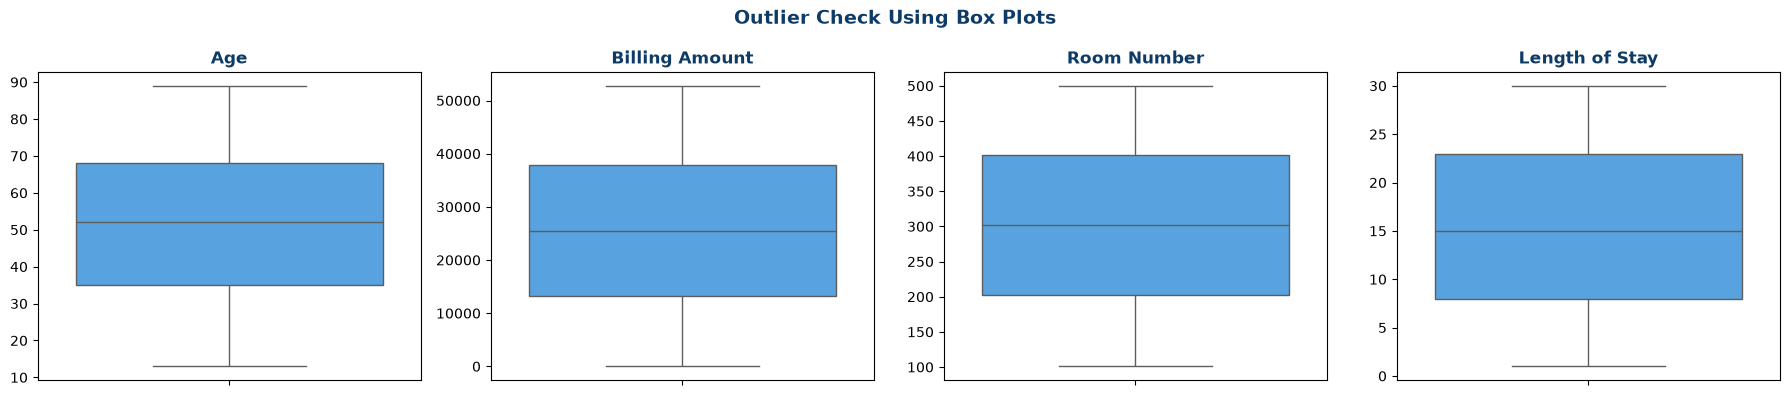

In [43]:
# Box plots of the numeric columns
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=healthcare_df[col], ax=ax, color="#42A5F5", flierprops={"markerfacecolor": "#E57373", "markeredgecolor": "#E57373"})
    ax.set_title(col, color="#0D3B66", fontweight="bold")
    ax.set_ylabel("")
fig.suptitle("Outlier Check Using Box Plots", fontsize=14, fontweight="bold", color="#0D3B66")
plt.tight_layout()
plt.show()

**✅ Observation and Decision:** The IQR check and the box plots show **no outliers** in Age, Billing Amount, Room Number or Length of Stay. Every value lies inside the IQR limits, and the box plots show no points beyond the whiskers.

🚫 **No outlier handling is done** (no capping and no removal), because there is nothing to treat and removing valid records would only reduce the data. The only extreme values in the data were the negative billing amounts, and those were already handled in Step 9.

## 🗑️ Step 12: Remove Unwanted Columns and Rows
Columns and rows that add nothing to the analysis are removed. Duplicate rows were already removed in Step 7, and negative billing was corrected in Step 9, so only the columns are reviewed here.

In [44]:
# Check: number of unique values in the identifier-type columns
healthcare_df[["Name", "Doctor", "Hospital", "Room Number"]].nunique()

Name           39619
Doctor         39679
Hospital       39635
Room Number      400
dtype: int64

**✅ Observation:** No column or row was removed. `Name`, `Doctor` and `Hospital` are identifiers rather than analysis variables, but they are kept so the records stay complete. `Room Number` carries little analytical value and is retained only for reference. All rows passed the checks above.

## 🔎 Step 13: Filtering and Aggregating the Data

Before moving on to the analysis, I filtered the cleaned data to pick out specific groups of patients and summarised billing and length of stay with aggregate functions. This confirmed that the new columns work as intended and gave a first look at the numbers.

In [45]:
# Filtering: emergency admissions of patients aged 65 and above
senior_emergency = healthcare_df[(healthcare_df["Is Emergency"]) & (healthcare_df["Age"] >= 65)]
print("Emergency admissions of patients aged 65 and above:", len(senior_emergency))

# Filtering: long stays with an abnormal test result
long_abnormal = healthcare_df[(healthcare_df["Is Long Stay"]) & (healthcare_df["Is Abnormal Result"])]
print("Long stays with an abnormal test result:", len(long_abnormal))

Emergency admissions of patients aged 65 and above: 5642
Long stays with an abnormal test result: 9787


In [46]:
# Aggregation: summary of billing amount and length of stay
healthcare_df[["Billing Amount", "Length of Stay"]].agg(["count", "mean", "median", "min", "max"]).round(2)

,Billing Amount,Length of Stay
count,54966.00,54966.0
mean,25546.24,15.5
median,25542.75,15.0
min,9.24,1.0
max,52764.28,30.0


**✅ Observation:** There were 5,642 emergency admissions among patients aged 65 and above, and 9,787 long stays with an abnormal test result. After cleaning, billing averages about 25,546 per admission (median 25,543) and the average stay is 15.5 days (median 15). The billing average differs slightly from the raw data (25,539) because the duplicates were removed and the negative amounts were corrected. The filters and the summary both work on the cleaned data, which is ready for analysis.

## ✅ Step 14: Final Check and Cleaning Log

In [47]:
# Final quality checks
print("Final shape              :", healthcare_df.shape)
print("Missing values           :", healthcare_df.isnull().sum().sum())
print("Duplicate rows           :", healthcare_df.duplicated().sum())
print("Negative billing amounts :", (healthcare_df["Billing Amount"] < 0).sum())
print("Length of stay range     :", healthcare_df["Length of Stay"].min(), "to", healthcare_df["Length of Stay"].max(), "days")
print()
healthcare_df.info()

Final shape              : (54966, 27)
Missing values           : 0
Duplicate rows           : 0
Negative billing amounts : 0
Length of stay range     : 1 to 30 days

<class 'pandas.DataFrame'>
RangeIndex: 54966 entries, 0 to 54965
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Name                54966 non-null  str           
 1   Age                 54966 non-null  int64         
 2   Gender              54966 non-null  str           
 3   Blood Type          54966 non-null  str           
 4   Medical Condition   54966 non-null  str           
 5   Date of Admission   54966 non-null  datetime64[us]
 6   Doctor              54966 non-null  str           
 7   Hospital            54966 non-null  str           
 8   Insurance Provider  54966 non-null  str           
 9   Billing Amount      54966 non-null  float64       
 10  Room Number         54966 non-null  int64         
 11  Ad

In [48]:
# Display the cleaning log
pd.DataFrame(cleaning_log)

,Step,Issue,Action,Rows Affected
0,Data types,Date of Admission and Discharge Date stored as...,Converted both columns to datetime,55500
1,Name,"Random capitalisation, titles and suffixes","Removed titles and suffixes, applied proper case",55467
2,Doctor,Titles and suffixes inside names,"Removed titles and suffixes, applied proper case",2216
3,Hospital,Trailing commas and stray 'and' at the start o...,Removed commas and stray 'and',14525
4,Duplicates,Fully repeated records,"Removed duplicates, kept the first copy",534
5,Billing Amount,Negative billing amounts,Converted to positive values and rounded to 2 ...,106
6,New columns,Columns needed for analysis were missing,"Added 12 columns (length of stay, date parts, ...",0


In [49]:
# Compare the data before and after cleaning
comparison = pd.DataFrame({
    "Rows": [healthcare_data.shape[0], healthcare_df.shape[0]],
    "Columns": [healthcare_data.shape[1], healthcare_df.shape[1]],
    "Duplicate Rows": [healthcare_data.duplicated().sum(), healthcare_df.duplicated().sum()],
    "Negative Billing": [(healthcare_data["Billing Amount"] < 0).sum(), (healthcare_df["Billing Amount"] < 0).sum()]
}, index=["Before Cleaning", "After Cleaning"])
comparison

,Rows,Columns,Duplicate Rows,Negative Billing
Before Cleaning,55500,15,534,108
After Cleaning,54966,27,0,0


**✅ Observation:** The cleaned data has 54,966 rows and 27 columns, with no missing values, no duplicates and no negative billing amounts. Length of stay lies between 1 and 30 days.

## 💾 Step 15: Save the Cleaned Dataset

In [50]:
# Save the cleaned data as CSV and Excel files
healthcare_df.to_csv("healthcare_data.csv", index=False)
healthcare_df.to_excel("healthcare_data.xlsx", index=False)
print("Cleaned data saved as healthcare_data.csv and healthcare_data.xlsx")

Cleaned data saved as healthcare_data.csv and healthcare_data.xlsx


In [51]:
# Preview of the final cleaned data
healthcare_df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay,Admission Year,Admission Quarter,Admission Month,Admission Day,Billing Per Day,Age Group,Billing Category,Stay Category,Is Emergency,Is Abnormal Result,Is Long Stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,328,Urgent,2024-02-02,Paracetamol,Normal,2,2024,Q1,January,Wednesday,9428.14,18 to 34,Medium,Up to 1 Week,False,False,False
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,2019,Q3,August,Tuesday,5607.22,50 to 64,Medium,Up to 1 Week,True,False,False
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,205,Emergency,2022-10-07,Aspirin,Normal,15,2022,Q3,September,Thursday,1863.67,65 and Above,Medium,2 to 3 Weeks,True,False,True
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,2020,Q4,November,Wednesday,1263.66,18 to 34,High,Over 3 Weeks,False,True,True
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,458,Urgent,2022-10-09,Penicillin,Abnormal,20,2022,Q3,September,Monday,711.92,35 to 49,Low,2 to 3 Weeks,False,True,True


**Note:** `healthcare_data` is the raw DataFrame. `healthcare_df` is the cleaned DataFrame and is used for all further analysis. The saved files `healthcare_data.csv` and `healthcare_data.xlsx` contain the cleaned data, and the original file `healthcare_dataset.csv` is left unchanged.

### 📝 Summary of Data Pre-processing

| Step | What was found | What was done |
|---|---|---|
| Working copy | Raw data must stay unchanged | Created `healthcare_df` as a copy |
| Column names | Already clear and consistent | No renaming needed |
| Extra spaces | None in any text column | Strip step kept as a safety check |
| Data types | Two date columns stored as text | Converted to datetime, no invalid dates |
| Text values | Random capitals, titles and suffixes in names, stray `and` and commas in hospital names | Proper case, titles and suffixes removed, hospital names cleaned |
| Category values | Already consistent | No change needed |
| Duplicates | 534 exact duplicate rows | Removed, leaving 54,966 rows |
| Missing values | None | No imputation needed |
| Invalid values | 106 negative billing amounts | Converted to positive and rounded to 2 decimals |
| New columns | Columns needed for analysis were missing | Added 12 columns: length of stay, date parts, billing per day, age group, billing and stay categories, boolean flags |
| Outliers | None in Age, Billing Amount, Room Number or Length of Stay | Checked with numbers and box plots, no handling needed |
| Unwanted columns and rows | None | Nothing removed |
| Filtering and aggregating | Quick checks on the cleaned data | Worked as expected |
| Output | Cleaned data ready for analysis | Saved as `healthcare_data.csv` and `healthcare_data.xlsx` |


➡️ **Next Step:** The cleaned DataFrame `healthcare_df` is ready for Exploratory Data Analysis 